# MNIST: loading and visualization

Run the cells in order. Load MNIST using scikit-learn's [`fetch_openml`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_openml.html); the first run downloads the data and later runs reuse the local cache. The experiment below uses the repository's existing PyTorch learner.

`X` contains flattened images as `float32` NumPy arrays with intensities in `[0, 1]`, and `y` contains integer labels from 0 to 9. Images are reshaped to `(28, 28)` for plotting.

In [41]:
from pathlib import Path
import sys

cwd = Path.cwd()
ROOT = next(
    (path for path in (cwd, *cwd.parents)
     if (path / "src" / "algorithms.py").is_file()
     and (path / "experiments" / "__init__.py").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from within the project checkout.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from experiments.mnist import MNISTExperiment, describe_mnist, load_mnist
from experiments.plotting import experiment_plot_style

DATA_DIR = ROOT / "data"

## Load the training and test splits

Keep MNIST's standard ordering: the first 60,000 images form the training split and the last 10,000 form the test split. The test split is kept separate for evaluation.

In [42]:
data = load_mnist(DATA_DIR)

In [43]:
describe_mnist(data, DATA_DIR)

Cache: /Users/thierryrioual/Desktop/Princeton/Academics/Research/High-dimensional dynamics of ST/implementation/data
Training: 60,000 | Test: 10,000
Features: shape=(60000, 784), dtype=float32
Image shape: (28, 28)


## Binary MNIST trajectories from random initialization

Compare the same learner with pseudo-label weights $\pi=0$ (supervised only) and $\pi=5$ (self-training). In each repetition the models share the training pool, observed labels, held-out test set, and initial parameters. The negative digit is encoded as −1 and the positive digit as +1.

Iteration 0 records the random initialization before any updates. Both methods run the full configured horizon. These are empirical MNIST trajectories.

In [44]:
# Experiment configuration
save_csv = False  # Set to True to export per-iteration measurements.
negative_digit = 3
positive_digit = 8
class_proportions = [0.5, 0.2]
labeling_rate = 0.01

n_train = 6000
n_test = 1000
seeds = [42, 43, 44]

training_steps = 200
eta = 0.05
reg_lambda = 0.1
pi = 5.0
tau = 0.8

# Effective-process simulation
sample_particles = 2000  # at the default n_train, preserves every sample-type count exactly
particle_seed = 47      # added to the repetition seed, as in the paper's simulations

In [45]:
experiment = MNISTExperiment(
    ROOT, data,
    negative_digit=negative_digit,
    positive_digit=positive_digit,
    class_proportions=class_proportions,
    labeling_rate=labeling_rate,
    n_train=n_train,
    n_test=n_test,
    seeds=seeds,
    training_steps=training_steps,
    eta=eta,
    reg_lambda=reg_lambda,
    pi=pi,
    tau=tau,
    sample_particles=sample_particles,
    particle_seed=particle_seed,
)

### Sampling and centering

For a split of size $n$ with target positive proportion $p$, sample $\lfloor np+1/2\rfloor$ positive rows without replacement and fill the rest with negative rows. The training pool comes from the official training set and the held-out test sample from the official test set. Reveal $\lfloor n_{\rm train}\,\text{labeling rate}+1/2\rfloor$ labels, stratifying by the realized training proportion.

The pixels above already lie in $[0,1]$. Subtract the training pool mean from both splits and keep all 784 coordinates.

### Fitting and diagnostics

As in `approximation_accuracy.ipynb`, initialize the intercept at $b_0=0$ and draw $w_0\sim\mathcal N(0,I_d)$ using a seeded generator. Both methods use the repository's affine score $r=b+Xw/\sqrt d$, logistic loss, and ridge penalty $\lambda\lVert w\rVert^2/(2d)$. The selected pseudo-label term has weight $\pi/M$ per row, with $M$ the total unlabeled count. The learner uses step sizes $\eta$ for $b$ and $\eta d$ for $w$. A score of zero predicts +1, and the confidence cutoff is $|r|\geq\log(\tau/(1-\tau))$.

Fit using revealed labels and zeros to mark unlabeled rows, then score both trajectories. The threshold diagnostics are computed for both methods. For $\pi=0$, they describe which unlabeled rows pass the cutoff under the supervised model even though their weight in training is zero. Hidden labels enter only the post-fit diagnostics.

### Full experiment

Run each scenario for every configured seed. Positive counts and realized fractions are shown as positive / total. Subtract the positive count from the total to obtain the negative count.

In [49]:
runs_by_scenario = experiment.run_from_scratch()

| Requested p | Seed | Train | Labeled | Unlabeled  | Test |
|---:|---:|---:|---:|---:|---:|
| 0.5 | 42 | 3,000 / 6,000 (50.0%) | 30 / 60 (50.0%) | 2,970 / 5,940 (50.0%) | 500 / 1,000 (50.0%) |
| 0.5 | 43 | 3,000 / 6,000 (50.0%) | 30 / 60 (50.0%) | 2,970 / 5,940 (50.0%) | 500 / 1,000 (50.0%) |
| 0.5 | 44 | 3,000 / 6,000 (50.0%) | 30 / 60 (50.0%) | 2,970 / 5,940 (50.0%) | 500 / 1,000 (50.0%) |
| 0.2 | 42 | 1,200 / 6,000 (20.0%) | 12 / 60 (20.0%) | 1,188 / 5,940 (20.0%) | 200 / 1,000 (20.0%) |
| 0.2 | 43 | 1,200 / 6,000 (20.0%) | 12 / 60 (20.0%) | 1,188 / 5,940 (20.0%) | 200 / 1,000 (20.0%) |
| 0.2 | 44 | 1,200 / 6,000 (20.0%) | 12 / 60 (20.0%) | 1,188 / 5,940 (20.0%) | 200 / 1,000 (20.0%) |

### Trajectories from iteration 0

The six panels follow the layout of `approximation_accuracy.ipynb`. Use held-out classification error and half the difference in mean scores between the positive and negative test classes in place of the model-based error and alignment. The selected error fraction counts wrong selected pseudo-labels divided by all unlabeled rows, matching the denominator in the reference notebook. The CSV also records class-specific test errors and accuracy conditional on selection.

Solid lines and bands show the mean and ± one standard deviation across repetitions.

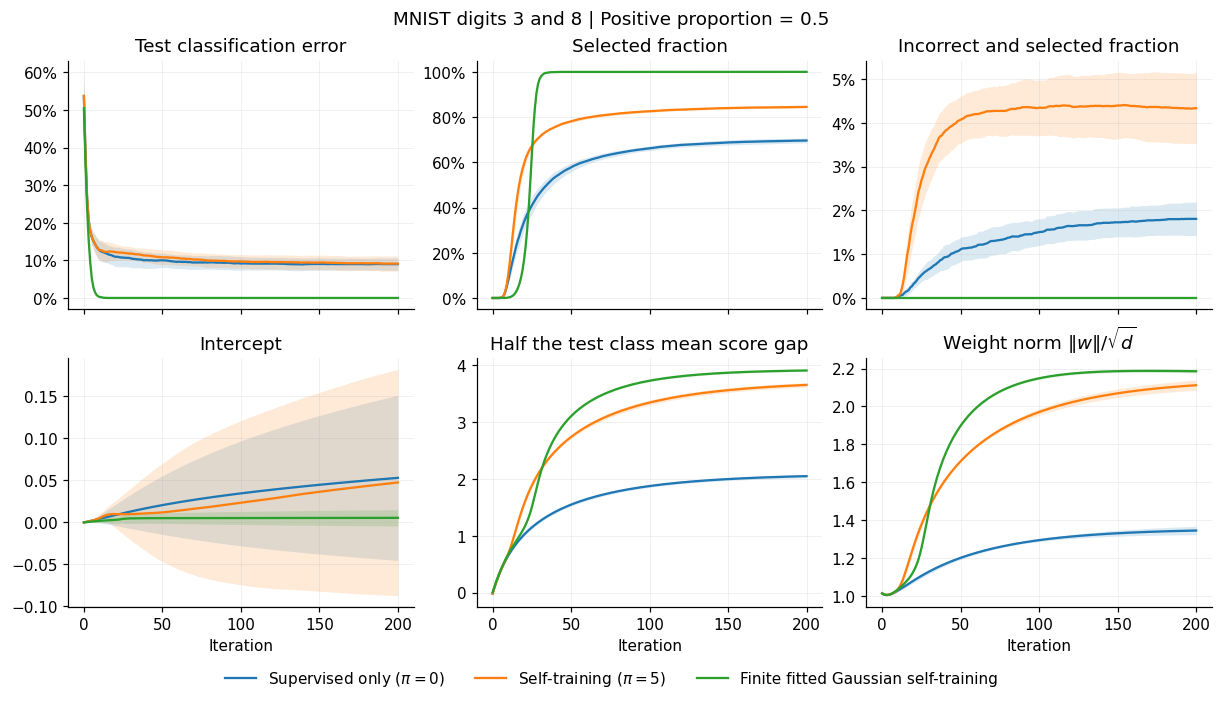

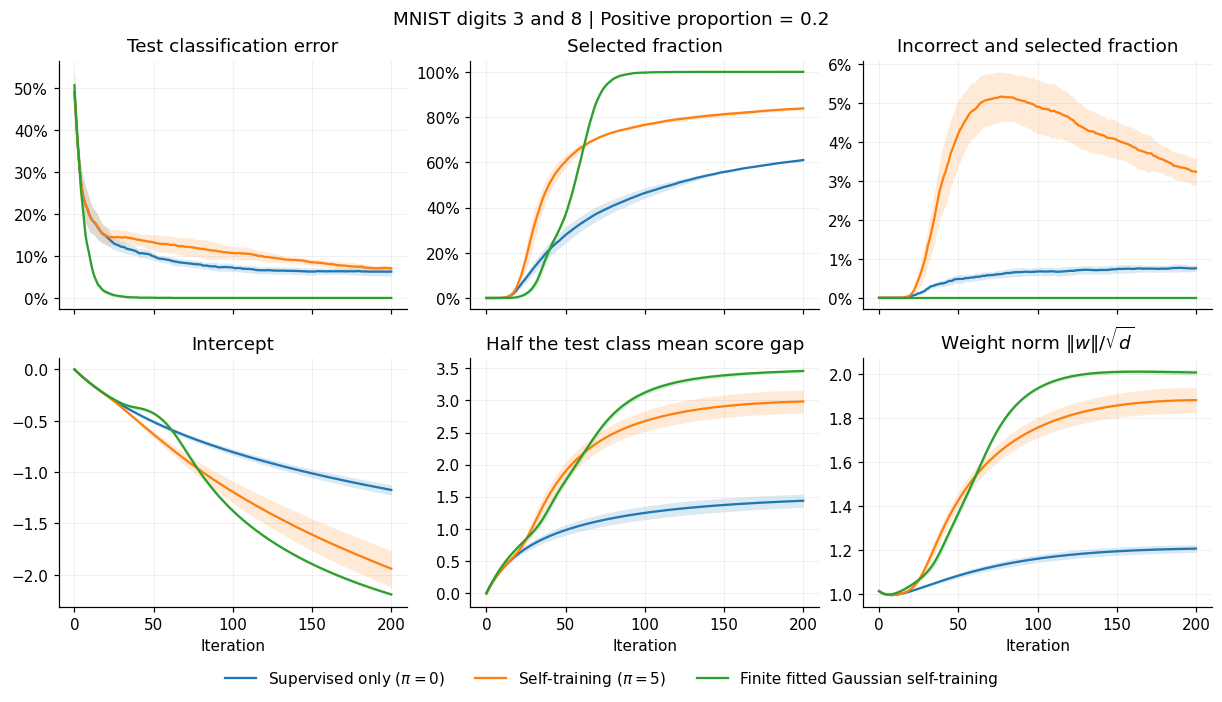

In [50]:
with experiment_plot_style():
    experiment.show_from_scratch_figures(runs_by_scenario)

In [51]:
experiment.save_from_scratch_measurements(runs_by_scenario, save_csv=save_csv)

| Requested p | Pseudo-label weight | Initial test error | Final test error | Final selected fraction |
|---:|---:|---:|---:|---:|
| 0.5 | 0 | 53.73% | 9.00% | 69.64% |
| 0.5 | 5 | 53.73% | 9.13% | 84.51% |
| 0.2 | 0 | 49.07% | 6.30% | 61.02% |
| 0.2 | 5 | 49.07% | 7.07% | 83.85% |

Per-iteration measurements saved to /Users/thierryrioual/Desktop/Princeton/Academics/Research/High-dimensional dynamics of ST/implementation/outputs/mnist_self_training/from_scratch_trajectories.csv


## MNIST versus a fitted-Gaussian effective process

This experiment assesses whether an isotropic Gaussian model calibrated from training data reproduces self-training trajectories on MNIST. Agreement concerns the displayed observables and does not establish Gaussianity of the underlying data.

The recursion models opposite class means. For each scenario and seed, use the two class means of the same scaled training pool to fit the midpoint $c$, half-difference $v$, and common within-class variance. Rerun only MNIST self-training after subtracting $c$ from both the training and test features. The Gaussian model in these coordinates has signal $\mu=\sqrt d\,v$ and noise scale $\sigma$. Hidden training labels determine the oracle calibration and midpoint; the finite learner receives the transformed features and revealed labels. No test observations enter the calibration.

All three runs start at $b_0=0$ with the same joint empirical law of $(\mu_i,w_{0i})$, using the original Gaussian initialization seed. The effective process uses every paired coordinate once. Its sample particles use the empirical joint frequencies of label and revelation status, with counts rounded to fit the particle budget. The learner and recursion share the finite learner's configuration, including the logistic loss, ridge penalty, confidence threshold, and unlabeled loss denominator $M$. All three record iterations 0 through $T$.

The effective process uses Gaussian population test error. The finite Gaussian learner uses an independently drawn test sample with matched class counts. The MNIST error uses the same class weights, which agrees with the earlier empirical error when the test count realizes the target proportion exactly. Selection metrics use the current training scores in all runs.

### Calibrate and compare

### Run the comparison and plot the trajectories

Lines show means and shading shows ± one standard deviation across repetitions. The shading describes variation across repetitions.

In [55]:
gaussian_comparison_runs = experiment.run_gaussian_comparison()

| Target p | Seed | d | n | Classes (− / +) | Revealed (− / +) | Sigma | ‖μ‖²/d | Initialization | Centering |
|---:|---:|---:|---:|:---:|:---:|---:|---:|:---|:---|
| 0.5 | 42 | 784 | 6000 | 3000 / 3000 | 30 / 30 | 0.2401 | 3.2881 | Seeded Gaussian weights, zero intercept | Oracle midpoint |
| 0.5 | 43 | 784 | 6000 | 3000 / 3000 | 30 / 30 | 0.2405 | 3.4081 | Seeded Gaussian weights, zero intercept | Oracle midpoint |
| 0.5 | 44 | 784 | 6000 | 3000 / 3000 | 30 / 30 | 0.2403 | 3.2976 | Seeded Gaussian weights, zero intercept | Oracle midpoint |
| 0.2 | 42 | 784 | 6000 | 4800 / 1200 | 48 / 12 | 0.2397 | 3.2236 | Seeded Gaussian weights, zero intercept | Oracle midpoint |
| 0.2 | 43 | 784 | 6000 | 4800 / 1200 | 48 / 12 | 0.2397 | 3.3320 | Seeded Gaussian weights, zero intercept | Oracle midpoint |
| 0.2 | 44 | 784 | 6000 | 4800 / 1200 | 48 / 12 | 0.2396 | 3.1481 | Seeded Gaussian weights, zero intercept | Oracle midpoint |

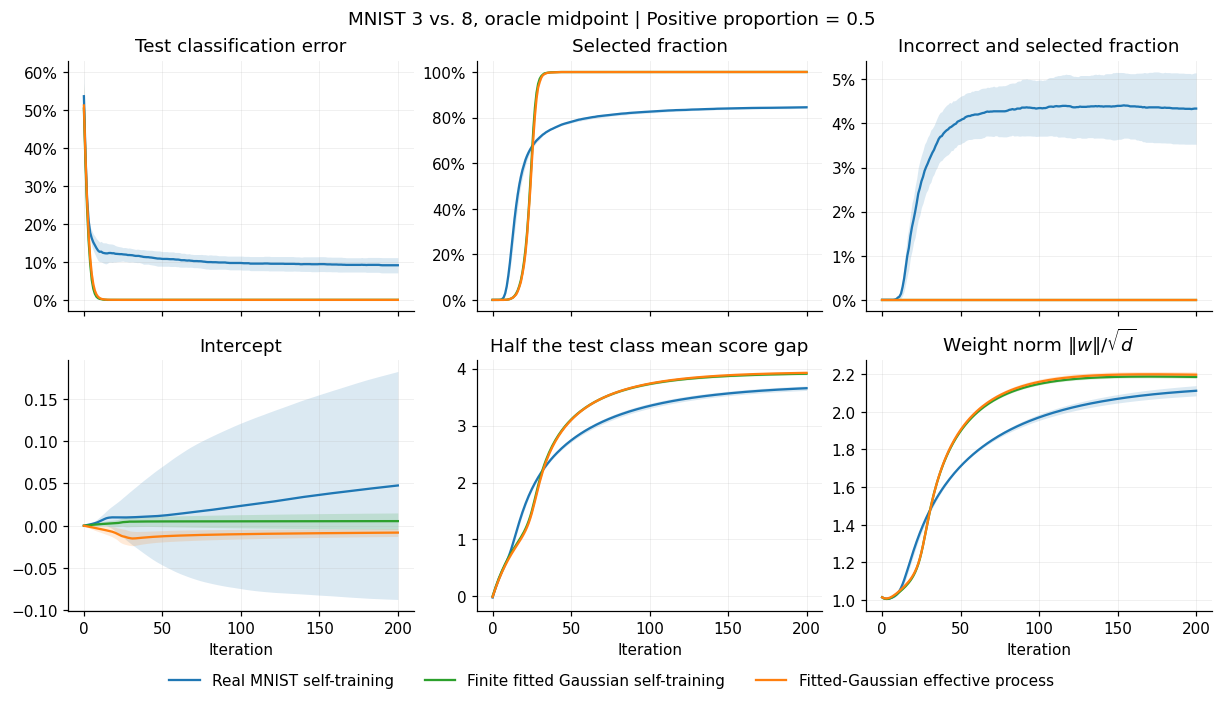

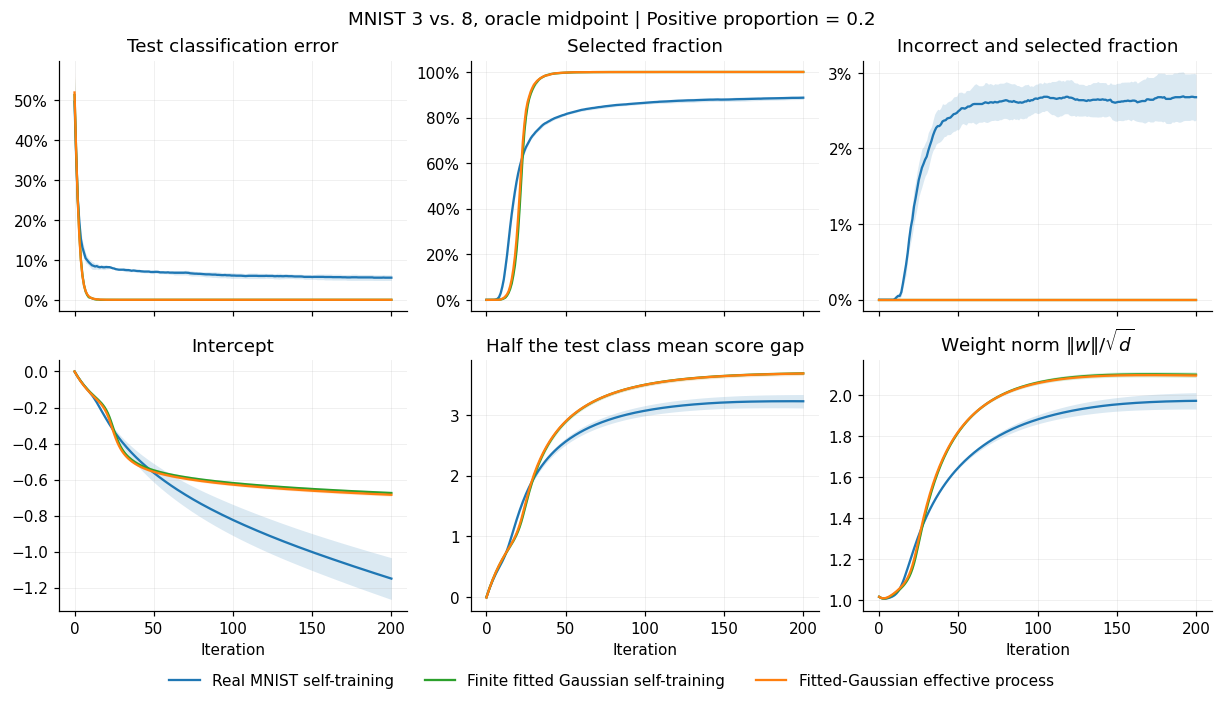

In [56]:
with experiment_plot_style():
    experiment.show_gaussian_figures(gaussian_comparison_runs)

## Whitened MNIST versus a fitted-Gaussian effective process

Fit the pooled within-class covariance $\widehat\Sigma$ on each training pool using its oracle labels. Apply the common map $x\mapsto (\widehat\Sigma+\epsilon I)^{-1/2}(x-\widehat c)$ to the training and test images. Here $\widehat c$ is the training midpoint and $\epsilon$ is a fixed fraction of the mean within-class pixel variance, $\mathrm{tr}(\widehat\Sigma)/d$. Regularization keeps all 784 features and limits amplification of low-variance directions.

The training covariance eigenvalues then become $\lambda_j/(\lambda_j+\epsilon)$. Whitening targets the pooled covariance and can leave differences between the classes and non-Gaussian score distributions. The transformation is estimated from the same training pool, making this an empirical comparison.

Reuse the original splits, revealed labels, initialization seeds, and update settings. Fit the isotropic Gaussian model again in whitened coordinates using the training pool. The learner receives the transformed features and only the revealed labels. The test pool uses the fitted transform and enters evaluation only. The new figures use the same six panels and show mean ± one standard deviation across repetitions.

In [57]:
# Whitening ridge relative to the mean within-class pixel variance.
whitening_ridge_fraction = 0.01

In [59]:
whitened_gaussian_runs = experiment.run_pooled_whitening(whitening_ridge_fraction)

| Target p | Seed | Whitening ridge | Directions with variance ≥ 0.9 | Fitted σ | ‖μ‖²/d |
|---:|---:|---:|---:|---:|---:|
| 0.5 | 42 | 0.000577 | 315 / 784 | 0.745 | 4.052 |
| 0.5 | 43 | 0.000579 | 317 / 784 | 0.746 | 4.104 |
| 0.5 | 44 | 0.000577 | 318 / 784 | 0.747 | 4.193 |
| 0.2 | 42 | 0.000574 | 311 / 784 | 0.747 | 4.650 |
| 0.2 | 43 | 0.000574 | 309 / 784 | 0.745 | 4.543 |
| 0.2 | 44 | 0.000574 | 310 / 784 | 0.746 | 4.549 |

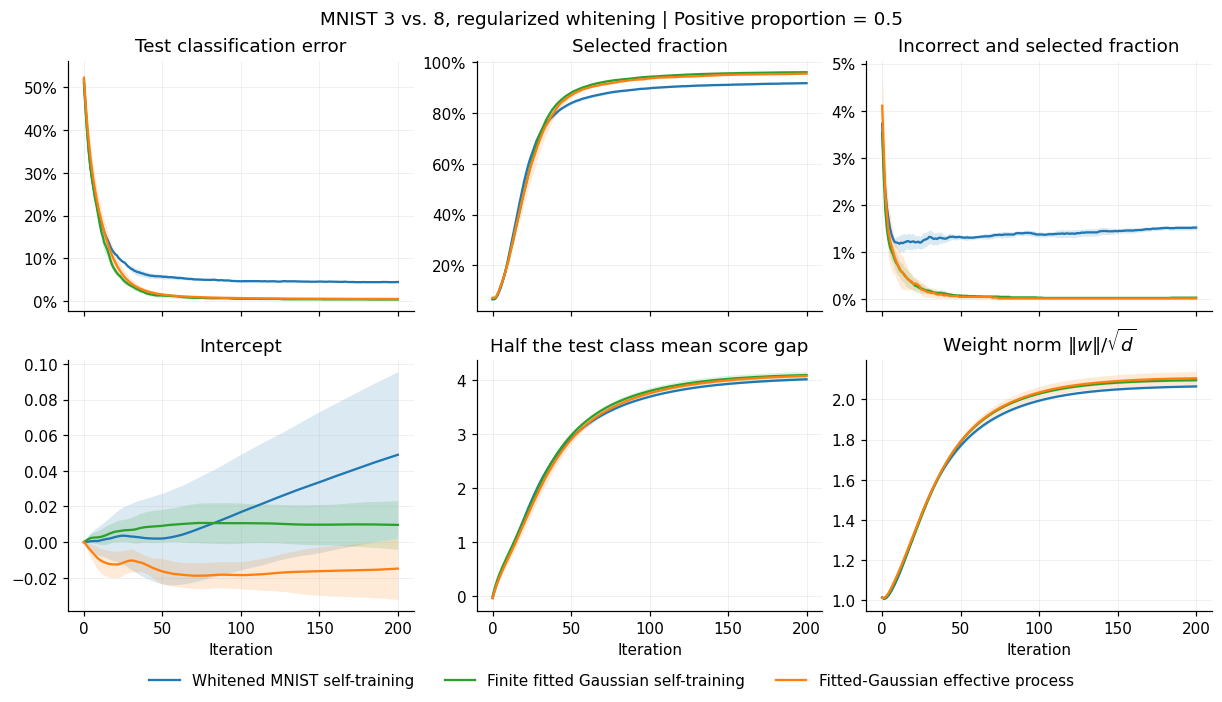

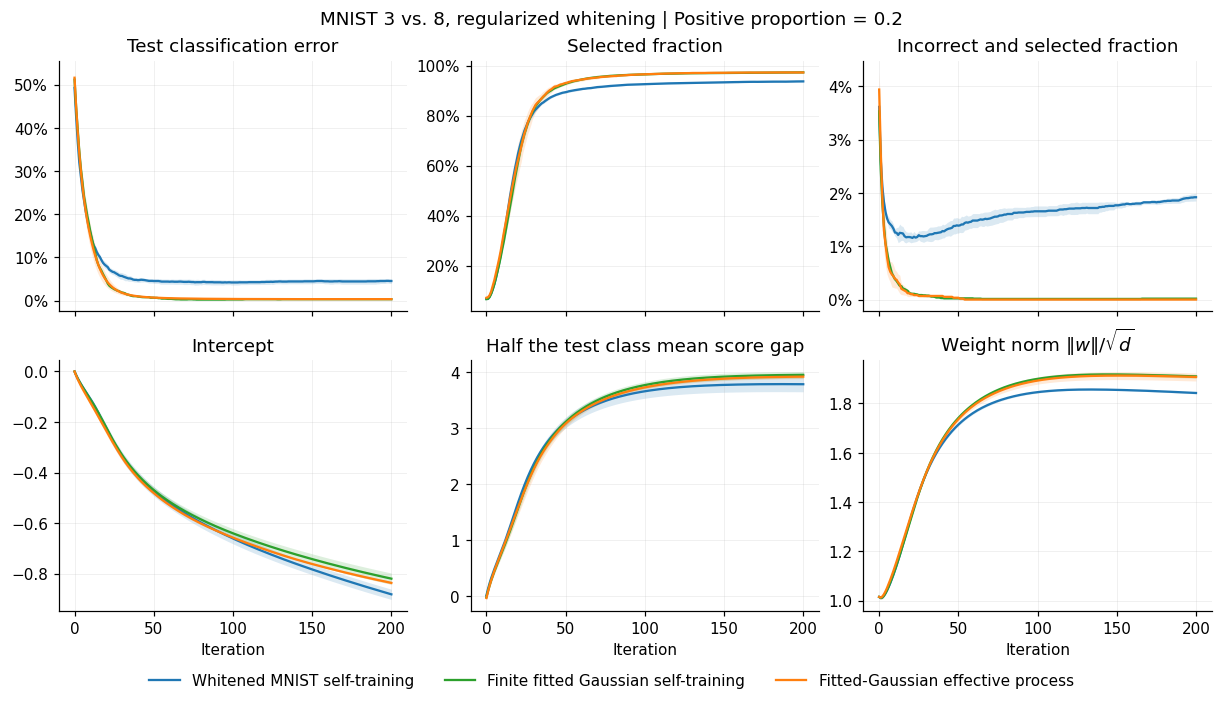

In [60]:
with experiment_plot_style():
    experiment.show_pooled_whitening_figures(whitened_gaussian_runs)

## Class-specific whitening versus the fitted-Gaussian effective process

Replace the shared residual whitener with one matrix per class. As before, estimate everything on the training pool. Let $A$ be the pooled whitener, $c$ the class midpoint, $m_y$ the class mean, and $A_y=(\widehat\Sigma_y+\epsilon I)^{-1/2}$ the whitener fitted within class $y$. Use the same ridge $\epsilon$ as the pooled run. Transform an image of class $y$ to
$$
A_y(x-m_y)+A(m_y-c).
$$
The training class means remain exactly those of the pooled-whitening experiment, so the half-difference is $A(m_+-m_-)/2$. There is no new signal parameter to choose. Refit the Gaussian noise scale in the new coordinates, since the residual variances can change.

This is an oracle comparison: the true digit selects the residual transform for each image, including unlabeled and test images. Test observations are excluded from estimating the transforms. The learner, particle recursion, splits, and seeds are the same as in the pooled-whitening experiment.

The table reports the relative training class covariance difference $\|C_+-C_-\|_F/\|(C_++C_-)/2\|_F$ under both transforms. Smaller values mean the class covariances are closer.

In [67]:
class_whitened_gaussian_runs = experiment.run_class_whitening(whitening_ridge_fraction)

| Target p | Seed | Covariance gap, pooled | Covariance gap, class-specific | Fitted σ |
|---:|---:|---:|---:|---:|
| 0.5 | 42 | 1.175 | 0.377 | 0.718 |
| 0.5 | 43 | 1.175 | 0.368 | 0.720 |
| 0.5 | 44 | 1.168 | 0.374 | 0.721 |
| 0.2 | 42 | 1.333 | 0.409 | 0.726 |
| 0.2 | 43 | 1.327 | 0.405 | 0.724 |
| 0.2 | 44 | 1.328 | 0.408 | 0.725 |

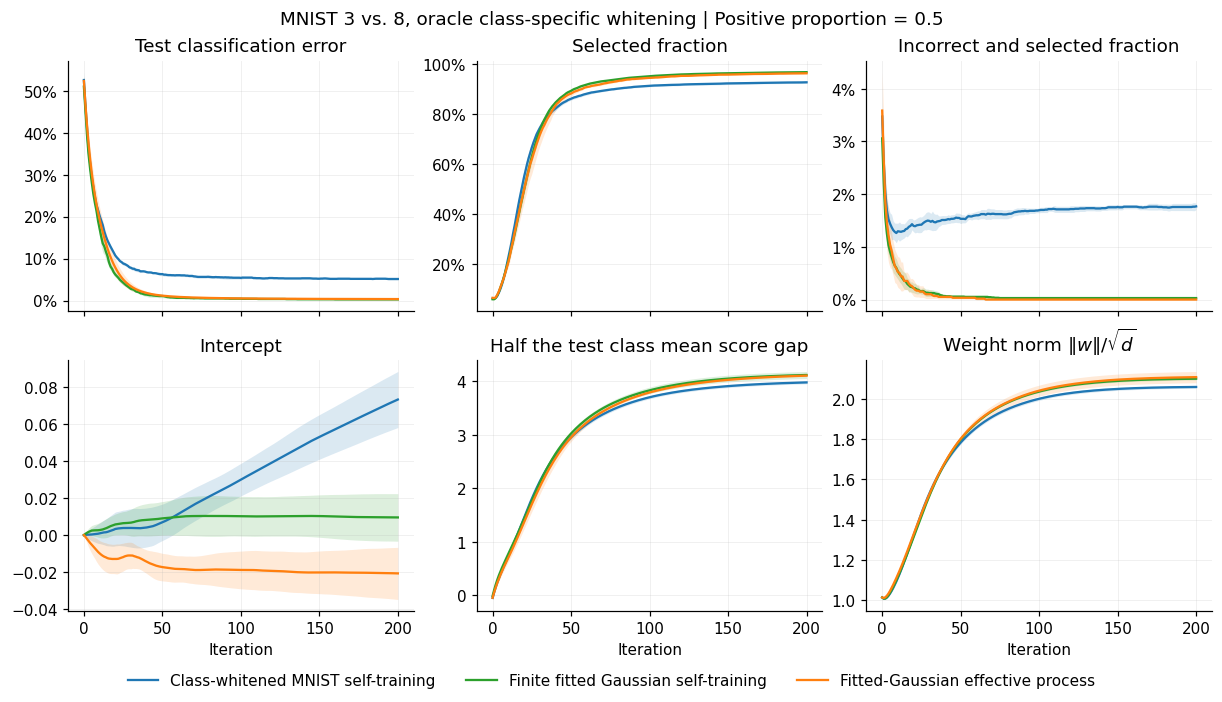

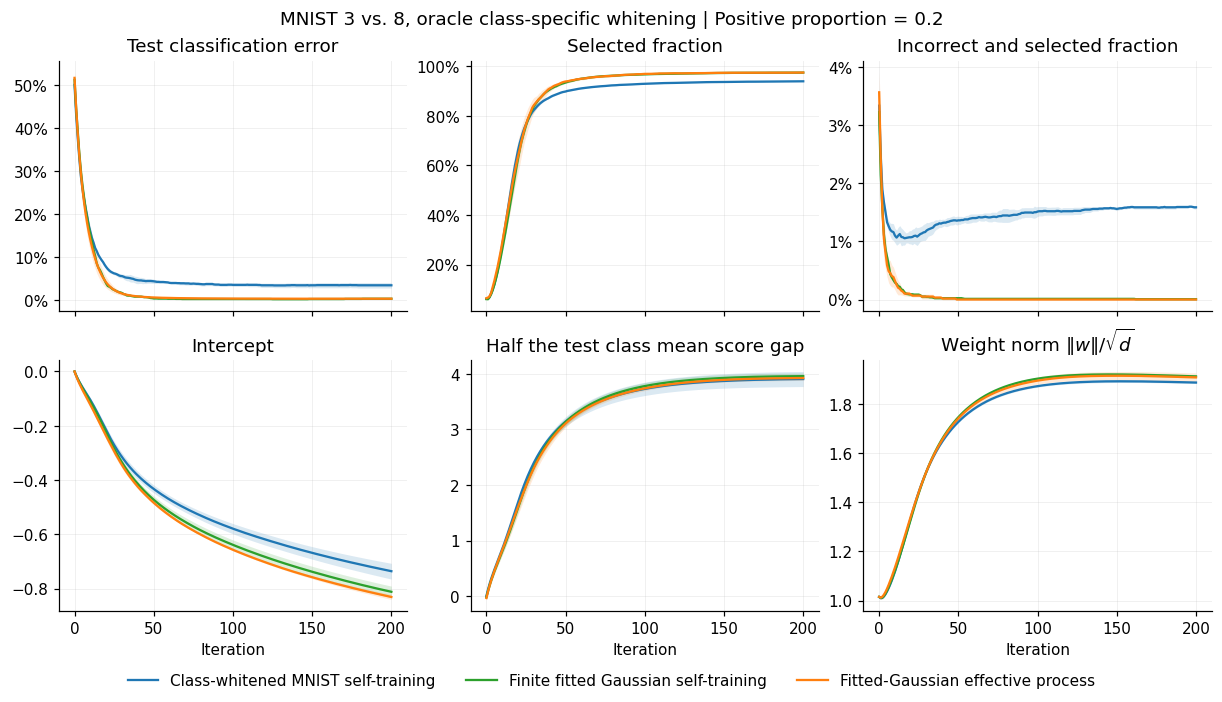

In [68]:
with experiment_plot_style():
    experiment.show_class_whitening_figures(class_whitened_gaussian_runs)